# Module sinh đường cong Elliptic mẫu trên $\mathbb{F}_p$

> **Topic 14 – ECC Cryptanalysis · Track A (generic ECDLP search)** <br>
> **Task:** *Module sinh đường cong Elliptic đơn giản trên Fp*

### Quá trình

| Bước | Nội dung | Hàm / lớp chính |
|---|---|---|
| 0 | Thư viện và hằng số | `D1_COLUMNS`, `Point` |
| 1 | Số học cơ bản | `is_prime`, `random_prime`, `factorize`, `sqrt_mod` |
| 2 | Đường cong và phép toán nhóm | `Curve` |
| 3 | Đếm số điểm $\#E(\mathbb{F}_p)$ | `count_points_naive`, `count_points_bsgs` |
| 4 | Phân loại, dựng bản ghi D1 | `classify`, `make_row` |
| 5 | Bộ sinh đường cong | `generate_curve` |
| 6 | Kiểm chứng toán học | `verify_row` |
| 7 | Đọc/ghi CSV chuẩn D1 | `write_csv`, `load_csv` |
| 8 | Selftest và CLI | `selftest`, `main` |
| 9 | **Chạy mẫu (demo)** | sinh D1 mẫu, kiểm chứng, so sánh hiệu năng |

<br>

> **Chỉ dùng cho mục đích học thuật.** Đường cong 16–48 bit là bản mẫu nhỏ để đo thuật toán tấn công và tuyệt đối không dùng làm tham số mật mã thật.

## Cơ sở lý thuyết

**1. Dạng Weierstrass ngắn.** Với $p>3$ nguyên tố:
$$E:\; y^2 = x^3 + ax + b \pmod p$$
Đường cong **không suy biến** khi biệt thức $\Delta = 4a^3 + 27b^2 \not\equiv 0 \pmod p$ <br> (hàm `Curve.is_nonsingular`).

**2. Nhóm các điểm.** Tập $E(\mathbb{F}_p)$ cùng điểm vô cực $\mathcal{O}$ tạo thành nhóm Abel. Phép cộng affine dùng hệ số góc $\lambda$:
- $P\ne Q$: $\lambda = \dfrac{y_2-y_1}{x_2-x_1}$ ; $P=Q$: $\lambda = \dfrac{3x_1^2 + a}{2y_1}$
- $x_3 = \lambda^2 - x_1 - x_2,\quad y_3 = \lambda(x_1 - x_3) - y_1$

Nhân vô hướng $kP$ dùng **double-and-add** (độ phức tạp $O(\log k)$ phép cộng).

**3. Định lý Hasse.** $\#E(\mathbb{F}_p) = p + 1 - t$ với $|t| \le 2\sqrt{p}$. <br>
Khoảng $[p+1-2\sqrt p,\; p+1+2\sqrt p]$ chứa $\#E$ – nền tảng của việc đếm điểm bằng BSGS.

**4. Cấu trúc bậc.** Ta có: $\#E = h\cdot n$ với $n$ = bậc điểm cơ sở $G$ (bậc nhóm con), $h$ = cofactor. <br>
Với ECDLP $Q = dG$, độ khó phụ thuộc **thừa số nguyên tố lớn nhất của $n$**:
- $n$ nguyên tố, $h=1$ → `safe_prime_order` (khó nhất với tấn công generic, $\approx\sqrt n$)
- $n$ nguyên tố, $h>1$ → `cofactor_gt1`
- $n$ chỉ gồm ước nhỏ ($B$-smooth) → `smooth_order` (**Pohlig–Hellman** phá được: $\approx\sum \sqrt{q_i}$)

**5. Hai trường hợp đặc biệt cần loại** (mặc định `allow_special=False`):
- *Anomalous* $\#E = p$ → tấn công Smart/SSSA giải ECDLP trong thời gian đa thức
- *Supersingular* $\#E = p+1$ (vết $t=0$) → MOV/Frey–Rück đưa về DLP trong trường mở rộng

**6. Đếm điểm.** 
- Với $p$ nhỏ: duyệt mọi $x$ ($O(p)$). 
- Với $p$ lớn hơn: chọn điểm ngẫu nhiên $P$, tìm mọi bội của bậc $P$ trong khoảng Hasse bằng **baby-step giant-step**, chi phí $\approx O(p^{1/4})$ phép nhóm. Lặp với nhiều điểm để thu hẹp về đúng một điểm duy nhất.

*Tài liệu chi tiết xem mục "Tài liệu tham khảo" ở cuối notebook.*

## Bước 0 – Thư viện và hằng số

- `Point = Optional[Tuple[int,int]]`: một điểm là cặp `(x, y)` hoặc `None` (điểm vô cực $\mathcal{O}$).
- `D1_COLUMNS`: **thứ tự cột** của CSV D1, phải khớp `row_schema` trong `data/schema_definition.json`.
- Ba tập `_JSON_COLUMNS`, `_BOOL_COLUMNS`, `_INT_COLUMNS` cho biết cột nào cần serialize đặc biệt khi ghi/đọc CSV.
- `NAIVE_COUNT_LIMIT = 2^16`: $p$ nhỏ hơn ngưỡng này thì đếm trực tiếp.

In [10]:
from __future__ import annotations
import argparse
import csv
import json
import random
import subprocess
import sys
import math, time 
from collections import Counter
from dataclasses import dataclass
from datetime import datetime, timezone
from math import gcd, isqrt
from pathlib import Path
from typing import Dict, List, Optional, Tuple

In [11]:
# Tự động dò tìm thư mục gốc dự án (chứa thư mục curves/) bất kể mở notebook từ đâu
cwd = Path.cwd().resolve()
ROOT_DIR = next((p for p in [cwd, *cwd.parents] if (p / "curves").is_dir()), cwd)
SCRIPTS_DIR = ROOT_DIR / "scripts"

for path in (str(ROOT_DIR), str(SCRIPTS_DIR)):
    if path not in sys.path:
        sys.path.insert(0, path)

Point = Optional[Tuple[int, int]]  # None = điểm vô cực O
GENERATION_METHOD = "toy_curve_gen.v1"
NAIVE_COUNT_LIMIT = 1 << 16  # p nhỏ hơn ngưỡng này -> đếm điểm trực tiếp

# Thứ tự cột CSV = thứ tự thuộc tính trong row_schema của D1.
D1_COLUMNS = [
    "curve_id", "curve_name", "p", "a", "b", "discriminant", "discriminant_ok",
    "E_count", "E_count_factorization", "base_point_x", "base_point_y",
    "subgroup_n", "n_bits", "n_factorization", "cofactor_h",
    "largest_prime_factor_n", "is_anomalous", "is_supersingular", "category",
    "source_for_point_class", "small_order_available", "generation_method",
    "seed", "notes", "git_commit","created_at",
]

_JSON_COLUMNS = {"E_count_factorization", "n_factorization", "small_order_available"}
_BOOL_COLUMNS = {"discriminant_ok", "is_anomalous", "is_supersingular"}
_INT_COLUMNS = {"n_bits", "seed"}

## Bước 1 – Số học cơ bản

### 1a. Kiểm tra nguyên tố và sinh số nguyên tố
**Miller–Rabin tất định:** Ta có: $n-1 = 2^s d$ ($d$ lẻ). <br>
Với mỗi cơ sở $a$, $n$ đủ điều kiện nếu $a^d \equiv \pm1$ hoặc $a^{2^r d}\equiv -1$ với một $r<s$. <br>
Dùng 12 cơ sở nguyên tố đầu tiên (2…37) thì kết quả **đúng chắc chắn với $n < 3{,}3\times10^{24}$** – đủ cho $p\le 48$ bit.

`random_prime(rng, bits)` đặt bit cao nhất và bit thấp nhất bằng 1 (đúng `bits` bit, số lẻ) rồi thử đến khi nguyên tố. Dùng `random.Random(seed)`.

In [12]:
_MR_BASES = (2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37)


def is_prime(n: int) -> bool:
    """Miller-Rabin tất định (đúng cho n < 3.3e24)."""
    if n < 2:
        return False
    for q in _MR_BASES:
        if n % q == 0:
            return n == q
    d, s = n - 1, 0
    while d % 2 == 0:
        d //= 2
        s += 1
    for a in _MR_BASES:
        x = pow(a, d, n)
        if x in (1, n - 1):
            continue
        for _ in range(s - 1):
            x = x * x % n
            if x == n - 1:
                break
        else:
            return False
    return True


def random_prime(rng: random.Random, bits: int) -> int:
    """Số nguyên tố ngẫu nhiên có đúng `bits` bit."""
    if bits < 8:
        raise ValueError("bits phải >= 8 cho toy curve")
    while True:
        cand = rng.getrandbits(bits) | (1 << (bits - 1)) | 1
        if is_prime(cand):
            return cand

In [13]:
# Chạy thử 
print("is_prime(2^31-1) =", is_prime(2**31 - 1), "(số nguyên tố Mersenne)")
print("is_prime(2^31+1) =", is_prime(2**31 + 1), "(chia hết cho 3)")
bit = int(input("Nhập số bit (>= 8) sinh số nguyên tố ngẫu nhiên: "))
p = random_prime(random.Random(1), bit)
print(f"random_prime {bit} bit:", p, "| số bit =", bit)

is_prime(2^31-1) = True (số nguyên tố Mersenne)
is_prime(2^31+1) = False (chia hết cho 3)
random_prime 24 bit: 10931917 | số bit = 24


### 1b. Phân tích thừa số: chia thử + Pollard's $\rho$
Cần phân tích $\#E$ ($\le 2^{49}$) và $n$ để phân loại đường cong.
1. **Chia thử** các ước $<5000$ (loại nhanh ước nhỏ).
2. Phần còn lại: nếu nguyên tố → xong. <br>
Ngược lại dùng **Pollard's $\rho$ (Floyd)**: dãy $x_{i+1} = x_i^2 + c \bmod n$, con trỏ "rùa–thỏ" $x, y$ và $\gcd(|x-y|, n)$ cho ước thực sự sau khoảng $\sqrt{q}$ bước ($q$ = ước nhỏ nhất).
3. Gọi đệ quy cho đến khi mọi thừa số đều nguyên tố.

`_pollard_rho` khởi tạo `random.Random(n)` ⇒ kết quả **tất định theo $n$**.

In [14]:
def _pollard_rho(n: int) -> int:
    """Trả về một ước nguyên thực sự của hợp số lẻ n (Floyd)."""
    rng = random.Random(n)  # tất định theo n
    while True:
        c = rng.randrange(1, n)
        x = y = rng.randrange(0, n)
        d = 1
        while d == 1:
            x = (x * x + c) % n
            y = (y * y + c) % n
            y = (y * y + c) % n
            d = gcd(abs(x - y), n)
        if d != n:
            return d


def factorize(n: int) -> Dict[int, int]:
    """Phân tích n thành thừa số nguyên tố {thừa số: số mũ}. Chia thử rồi Pollard rho."""
    if n < 1:
        raise ValueError("n phải >= 1")
    out: Dict[int, int] = {}
    d = 2
    while d < 5000 and d * d <= n:
        while n % d == 0:
            out[d] = out.get(d, 0) + 1
            n //= d
        d += 1 if d == 2 else 2

    def rec(m: int) -> None:
        if m == 1:
            return
        if is_prime(m):
            out[m] = out.get(m, 0) + 1
            return
        f = _pollard_rho(m)
        rec(f)
        rec(m // f)

    rec(n)
    return dict(sorted(out.items()))

In [15]:
# Chạy thử 
for v in (2**31 - 1, 600851475143, 999999000001 * 3):
    f = factorize(v)
    print(f"{v} = {f}   kiểm tra nhân lại:", math.prod(q**e for q, e in f.items()) == v)
    
num = int(input("Nhập số nguyên dương (>= 1) để phân tích thừa số nguyên tố: "))
f = factorize(num)
print(f"{num} = {f}   kiểm tra nhân lại:", math.prod(q**e for q, e in f.items()) == num)    

2147483647 = {2147483647: 1}   kiểm tra nhân lại: True
600851475143 = {71: 1, 839: 1, 1471: 1, 6857: 1}   kiểm tra nhân lại: True
2999997000003 = {3: 1, 999999000001: 1}   kiểm tra nhân lại: True
25520960 = {2: 6, 5: 1, 173: 1, 461: 1}   kiểm tra nhân lại: True


### 1c. Căn bậc hai modulo $p$ – Tonelli–Shanks
Cần để từ $x$ tính $y=\sqrt{x^3+ax+b}$ khi **sinh điểm ngẫu nhiên**. <br>
Đặt $n = x^3+ax+b \bmod p$.

**Bước 0 – Kiểm tra tồn tại (tiêu chuẩn Euler).** <br>
$n$ là thặng dư bậc hai $\iff n^{(p-1)/2}\equiv 1 \pmod p$. Nếu bằng $-1$ thì không có căn → trả `None`.

**Bước 1 – Trường hợp dễ: $p\equiv 3 \pmod 4$.** Căn là $r = n^{(p+1)/4}$, vì
$$r^2 = n^{(p+1)/2} = n\cdot n^{(p-1)/2} \equiv n \cdot 1 = n.$$

**Bước 2 – Trường hợp tổng quát: Tonelli–Shanks.** <br>
Cho $p-1 = q\cdot 2^s$ với $q$ lẻ. Nhóm nhân $\mathbb{F}_p^*$ có cấp $p-1$, nên phần tử có cấp là luỹ thừa của 2 nằm trong nhóm con $H$ cấp $2^s$.

Duy trì hai biến $r$ và $t$ sao cho **bất biến**
$$r^2 \equiv n\cdot t \pmod p$$
luôn đúng. Khởi tạo:
$$r = n^{(q+1)/2},\qquad t = n^{q}.$$
Kiểm tra: $r^2 = n^{q+1} = n\cdot n^q = n\cdot t$ ✓.

*Ý nghĩa của $t$:* $t$ là **sai số** (hệ số "dư") giữa $r^2$ và $n$. Nếu $t\equiv 1$ thì $r^2\equiv n$, tức $r$ chính là căn cần tìm. <br>
Mục tiêu của thuật toán là **ép $t\to 1$** mà vẫn giữ bất biến.

*Vì sao $t$ thuộc $H$:* do $n$ là thặng dư bậc hai nên $n^{(p-1)/2}=1$, suy ra
$$t^{2^{s-1}} = n^{q\cdot 2^{s-1}} = n^{(p-1)/2} = 1.$$
Vậy cấp của $t$ là $2^m$ với $m \le s-1$ (tức $t$ nằm trong $H$ và cấp của nó chia hết $2^{s-1}$).

*Vòng lặp "hạ bậc" $t$:* khi $t\ne 1$:

1. Tìm $m$ nhỏ nhất ($0<m<s$) sao cho $t^{2^m}\equiv 1$, tức $t$ có cấp đúng $2^m$.
2. Chọn trước một **non-residue** $z$ (thoả $z^{(p-1)/2}\equiv -1$) và đặt $c = z^q$. Khi đó $c$ có cấp **đúng** $2^s$ nên $c^{2^{s-1}}=-1$.
3. Tính $b = c^{2^{s-m-1}}$. Khi đó $b^{2^m} = c^{2^{s-1}} = -1$, và $b^{2^{m+1}}=1$.
4. Cập nhật:
$$r \leftarrow r\cdot b,\qquad t \leftarrow t\cdot b^2,\qquad c \leftarrow b^2,\qquad s \leftarrow m.$$

*Vì sao các bước này đúng:*

- **Bất biến được giữ:** $(rb)^2 = r^2 b^2 = (nt)\,b^2 = n\,(t b^2)$ ✓.
- **Cấp của $t$ giảm ít nhất 1 bậc:** $(t b^2)^{2^{m-1}} = t^{2^{m-1}}\cdot b^{2^m}$. Vì $t$ có cấp đúng $2^m$ nên $t^{2^{m-1}}=-1$, còn $b^{2^m}=-1$, nên tích bằng $(-1)(-1)=1$. Vậy $t b^2$ có cấp $\le 2^{m-1}$ < $2^m$.
- Do cấp của $t$ là luỹ thừa của 2 và **giảm nghiêm ngặt** sau mỗi vòng, sau tối đa $s-1$ vòng cấp của $t$ về $2^0=1$, tức $t\equiv 1$.

*Kết thúc:* khi $t\equiv 1$, bất biến cho $r^2\equiv n\cdot 1 = n$, nên $r$ là căn bậc hai cần tìm (căn còn lại là $p-r$).

In [16]:
def sqrt_mod(n: int, p: int) -> Optional[int]:
    """Căn bậc hai của n modulo p nguyên tố lẻ (Tonelli-Shanks); None nếu không có."""
    n %= p
    if n == 0:
        return 0
    if pow(n, (p - 1) // 2, p) != 1:
        return None
    if p % 4 == 3:
        return pow(n, (p + 1) // 4, p)
    q, s = p - 1, 0
    while q % 2 == 0:
        q //= 2
        s += 1
    z = 2
    while pow(z, (p - 1) // 2, p) != p - 1:
        z += 1
    m, c, t, r = s, pow(z, q, p), pow(n, q, p), pow(n, (q + 1) // 2, p)
    while t != 1:
        i, t2 = 0, t
        while t2 != 1:
            t2 = t2 * t2 % p
            i += 1
        b = pow(c, 1 << (m - i - 1), p)
        m, c = i, b * b % p
        t, r = t * c % p, r * b % p
    return r

In [17]:
# Chạy thử: p=41 ≡ 1 (mod 4) -> bắt buộc đi nhánh Tonelli–Shanks; p=43 ≡ 3 (mod 4) -> nhánh tắt
for p in (41, 43):
    squares = {x * x % p for x in range(1, p)}
    ok = all((sqrt_mod(n, p) ** 2) % p == n for n in squares)
    none_ok = all(sqrt_mod(n, p) is None for n in range(1, p) if n not in squares)
    print(f"p={p} (p%4={p % 4}): căn đúng cho mọi thặng dư = {ok}; trả None cho phi thặng dư = {none_ok}")

num = int(input("Nhập số nguyên dương (>= 1) để kiểm tra căn bậc hai modulo p: "))
p = int(input("Nhập số nguyên tố p lẻ: "))
if not is_prime(p) or p < 3:
    print(f"p={p} không phải số nguyên tố lẻ >= 3")
else:   
    sqrt = sqrt_mod(num, p)
    if sqrt is None:
        print(f"{num} không có căn bậc hai modulo {p}")
    else:
        print(f"Căn bậc hai của {num} modulo {p} là {sqrt} (kiểm tra: {sqrt**2 % p})")

p=41 (p%4=1): căn đúng cho mọi thặng dư = True; trả None cho phi thặng dư = True
p=43 (p%4=3): căn đúng cho mọi thặng dư = True; trả None cho phi thặng dư = True
Căn bậc hai của 43 modulo 43 là 0 (kiểm tra: 0)


## Bước 2 – Lớp `Curve`: đường cong và phép toán nhóm

`@dataclass(frozen=True)` → đối tượng bất biến, hashable, so sánh được. Các phương thức:

| Phương thức | Ý nghĩa |
|---|---|
| `discriminant`, `is_nonsingular` | $4a^3+27b^2 \bmod p$, loại đường cong suy biến |
| `rhs(x)`, `contains(P)` | vế phải $x^3+ax+b$; kiểm tra $P\in E$ |
| `neg(P)` | $-P=(x,-y)$ |
| `add(P,Q)` | cộng điểm affine; nghịch đảo modulo bằng `pow(·, -1, p)` |
| `mul(k,P)` | double-and-add; $k<0$ → nhân $-k$ với $-P$ |
| `random_point(rng)` | điểm ngẫu nhiên nhờ `sqrt_mod` |
| `point_order(P, N, factors)` | bậc của $P$ biết bội $N$ và thừa số của $N$: với mỗi ước nguyên tố $q$, chia $N$ cho $q$ chừng nào $\tfrac{N}{q}P=\mathcal{O}$ |
| `from_row`, `base_point_from_row` | tạo đối tượng từ bản ghi D1 |

In [18]:
@dataclass(frozen=True)
class Curve:
    """E: y^2 = x^3 + a*x + b trên F_p (p nguyên tố > 3)."""
    p: int
    a: int
    b: int

    def discriminant(self) -> int:
        return (4 * pow(self.a, 3, self.p) + 27 * self.b * self.b) % self.p

    def is_nonsingular(self) -> bool:
        return self.discriminant() != 0

    def rhs(self, x: int) -> int:
        return (x * x * x + self.a * x + self.b) % self.p

    def contains(self, P: Point) -> bool:
        if P is None:
            return True
        x, y = P
        return 0 <= x < self.p and 0 <= y < self.p and (y * y - self.rhs(x)) % self.p == 0

    def neg(self, P: Point) -> Point:
        return None if P is None else (P[0], (-P[1]) % self.p)

    def add(self, P: Point, Q: Point) -> Point:
        if P is None:
            return Q
        if Q is None:
            return P
        p = self.p
        x1, y1 = P
        x2, y2 = Q
        if x1 == x2:
            if (y1 + y2) % p == 0:
                return None
            lam = (3 * x1 * x1 + self.a) * pow(2 * y1, -1, p) % p
        else:
            lam = (y2 - y1) * pow(x2 - x1, -1, p) % p
        x3 = (lam * lam - x1 - x2) % p
        return (x3, (lam * (x1 - x3) - y1) % p)

    def mul(self, k: int, P: Point) -> Point:
        """Nhân vô hướng k*P bằng double-and-add."""
        if k < 0:
            return self.mul(-k, self.neg(P))
        R: Point = None
        while k:
            if k & 1:
                R = self.add(R, P)
            P = self.add(P, P)
            k >>= 1
        return R

    def random_point(self, rng: random.Random) -> Tuple[int, int]:
        """Điểm affine ngẫu nhiên (không phải O)."""
        while True:
            x = rng.randrange(self.p)
            y = sqrt_mod(self.rhs(x), self.p)
            if y is not None:
                return (x, y if rng.getrandbits(1) else (-y) % self.p)

    def point_order(self, P: Point, group_order: int, factors: Dict[int, int]) -> int:
        """Bậc của P, biết bội group_order của nó và phân tích thừa số của bội đó."""
        order = group_order
        for q in factors:
            while order % q == 0 and self.mul(order // q, P) is None:
                order //= q
        return order

    # -- (de)serialize với bản ghi D1 -------------------------------------
    @staticmethod
    def from_row(row: dict) -> "Curve":
        return Curve(int(row["p"]), int(row["a"]), int(row["b"]))

    @staticmethod
    def base_point_from_row(row: dict) -> Tuple[int, int]:
        return (int(row["base_point_x"]), int(row["base_point_y"]))

In [19]:
# Chạy thử: E: y^2 = x^3 + 2x + 3 trên F_97
E = Curve(97, 2, 3)
print("Δ =", E.discriminant(), "| không suy biến:", E.is_nonsingular())

P = (3, 6)
print("P ∈ E:", E.contains(P), "| 2P =", E.add(P, P), "| 3P =", E.mul(3, P))
print("P + (-P) =", E.add(P, E.neg(P)), "(None = điểm vô cực O)")

# Đếm tay: duyệt mọi (x, y)
points = [(x, y) for x in range(97) for y in range(97) if E.contains((x, y))]
N = len(points) + 1  # +1 cho O
print("#E (duyệt tay) =", N, "| (Bước 3 sẽ kiểm lại bằng count_points_naive)")

# Bậc của P: nhân dần cho tới khi về O
k, R = 1, P
while R is not None:
    R, k = E.add(R, P), k + 1
print("bậc của P =", k, "| chia hết #E:", N % k == 0, "(định lý Lagrange)")

# Kiểm tra tính kết hợp (P+Q)+R = P+(Q+R) trên 200 bộ ba ngẫu nhiên
rng = random.Random(0)
trip = [tuple(rng.choice(points) for _ in range(3)) for _ in range(200)]
print("Tính kết hợp đúng với 200 bộ ba:", all(E.add(E.add(a, b), c) == E.add(a, E.add(b, c)) for a, b, c in trip))

Δ = 81 | không suy biến: True
P ∈ E: True | 2P = (80, 10) | 3P = (80, 87)
P + (-P) = None (None = điểm vô cực O)
#E (duyệt tay) = 100 | (Bước 3 sẽ kiểm lại bằng count_points_naive)
bậc của P = 5 | chia hết #E: True (định lý Lagrange)
Tính kết hợp đúng với 200 bộ ba: True


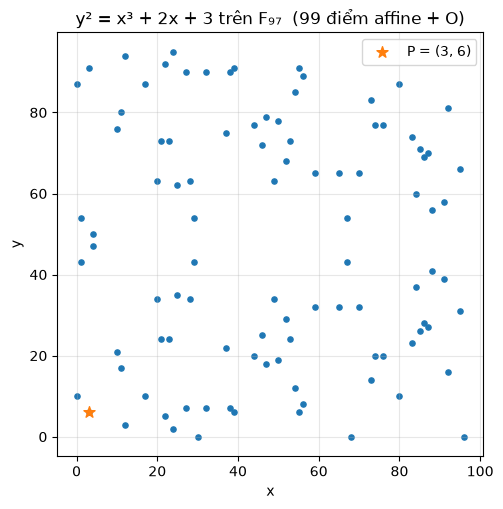

In [20]:
# Trực quan hoá các điểm của E trên F_97 (đồ thị là tập điểm rời rạc)
import matplotlib.pyplot as plt
xs, ys = zip(*points)
plt.figure(figsize=(5.5, 5.5))
plt.scatter(xs, ys, s=14)
plt.scatter(*P, s=70, marker="*", label="P = (3, 6)")
plt.title(f"y² = x³ + 2x + 3 trên F₉₇  ({len(points)} điểm affine + O)")
plt.xlabel("x"); plt.ylabel("y"); plt.grid(alpha=.3); plt.legend()
plt.show()

## Bước 3 – Đếm số điểm $\#E(\mathbb{F}_p)$

### 3a. Đếm trực tiếp $O(p)$ – `count_points_naive`
Lập bảng tần suất các bình phương `y*y % p` (`Counter`), rồi với mỗi $x$ cộng số nghiệm $y$ của $y^2 = x^3+ax+b$ (0, 1 hoặc 2). Cộng thêm 1 cho $\mathcal{O}$. Dùng cho $p<2^{16}$ và làm **chuẩn đối chiếu**.

### 3b. BSGS trên khoảng Hasse – `_hasse_candidates`, `count_points_bsgs`
Mục tiêu: tìm mọi $N\in[lo,hi]$ với $N\cdot P=\mathcal{O}$.
- Độ rộng khoảng $\approx 4\sqrt p$, chọn $m\approx\sqrt{hi-lo+1}$ ⇒ chi phí $\approx p^{1/4}$ phép nhóm.
- **Baby steps:** lưu $jP$ ($0\le j<m$) vào từ điển.
- **Giant steps:** bắt đầu từ $T=-lo\cdot P$, mỗi bước cộng $-mP$; nếu $T = jP$ thì $N = lo + i\,m + j$ thoả $NP=\mathcal{O}$.
- Một điểm cho **nhiều** điểm (chỉ cần $N$ là bội của bậc $P$). Hàm `count_points_bsgs` lấy giao các tập điểm qua nhiều điểm ngẫu nhiên cho tới khi còn **đúng 1** số.

> **Lưu ý học thuật:** thuật toán Mestre–Schoof "chuẩn" dùng thêm **đường cong xoắn bậc hai** (quadratic twist) để đảm bảo duy nhất điểm khi $p>229$. Bản code này dùng biến thể thực dụng hơn – giao điểm qua tối đa `max_points=40` điểm – và báo `RuntimeError` nếu không đạt tính duy nhất (khi đó `generate_curve` bỏ qua đường cong đó).

In [21]:
def count_points_naive(E: Curve) -> int:
    """Đếm trực tiếp O(p) -- chỉ dùng cho p nhỏ / kiểm chứng."""
    sq = Counter(y * y % E.p for y in range(E.p))
    return 1 + sum(sq.get(E.rhs(x), 0) for x in range(E.p))


def _hasse_candidates(E: Curve, P: Tuple[int, int], lo: int, hi: int) -> List[int]:
    """Mọi N trong [lo, hi] thoả N*P = O (baby-step giant-step)."""
    m = isqrt(hi - lo + 1) + 1
    baby: Dict[Point, List[int]] = {}
    R: Point = None
    for j in range(m):
        baby.setdefault(R, []).append(j)  # R = j*P
        R = E.add(R, P)
    giant_step = E.neg(R)                  # -m*P
    T = E.neg(E.mul(lo, P))                # -lo*P
    found: List[int] = []
    for i in range(m):
        for j in baby.get(T, ()):
            N = lo + i * m + j
            if N <= hi:
                found.append(N)
        T = E.add(T, giant_step)
    return found


def count_points_bsgs(E: Curve, rng: Optional[random.Random] = None,
                      max_points: int = 40) -> int:
    """Đếm #E bằng BSGS trên khoảng Hasse [p+1-2sqrt(p), p+1+2sqrt(p)]."""
    rng = rng or random.Random(E.p)
    w = 2 * isqrt(E.p) + 2
    lo, hi = E.p + 1 - w, E.p + 1 + w
    cands: Optional[List[int]] = None
    for _ in range(max_points):
        P = E.random_point(rng)
        if cands is None:
            c = _hasse_candidates(E, P, lo, hi)
            if len(c) > 10000:  # bậc điểm quá nhỏ, thử điểm khác
                continue
            cands = c
        else:
            cands = [N for N in cands if E.mul(N, P) is None]
        if len(cands) == 1:
            return cands[0]
        if not cands:
            raise RuntimeError("count_points_bsgs: không còn ứng viên (lỗi nội bộ)")
    raise RuntimeError("count_points_bsgs: không xác định được duy nhất #E")


def count_points(E: Curve, rng: Optional[random.Random] = None) -> int:
    return count_points_naive(E) if E.p < NAIVE_COUNT_LIMIT else count_points_bsgs(E, rng)

In [22]:
# Chạy thử 3: so khớp naive và BSGS, đo thời gian
rng = random.Random(42)
for bits in (14, 18, 20):
    p = random_prime(rng, bits)
    E = Curve(p, rng.randrange(p), rng.randrange(p))
    if not E.is_nonsingular():
        continue
    t0 = time.perf_counter(); n1 = count_points_naive(E); t1 = time.perf_counter()
    n2 = count_points_bsgs(E, rng);                       t2 = time.perf_counter()
    w = 2 * isqrt(p) + 2
    print(f"p={p:>8} ({bits} bit) | Hasse: [{p + 1 - w}, {p + 1 + w}] | naive={n1} ({t1 - t0:.3f}s) "
          f"bsgs={n2} ({t2 - t1:.4f}s) | khớp: {n1 == n2}")

# p lớn (40 bit): chỉ BSGS khả thi
p = random_prime(random.Random(7), 40)
E = Curve(p, 12345, 67890)
t0 = time.perf_counter(); N = count_points(E); dt = time.perf_counter() - t0
print(f"\np 40-bit = {p}: #E = {N} (BSGS, {dt:.3f}s) | t = p+1-#E = {p + 1 - N}, |t| <= 2√p: {abs(p + 1 - N) <= 2 * isqrt(p) + 2}")

p=   10477 (14 bit) | Hasse: [10272, 10684] | naive=10615 (0.010s) bsgs=10615 (0.0002s) | khớp: True
p=  233879 (18 bit) | Hasse: [232912, 234848] | naive=234048 (0.110s) bsgs=234048 (0.0001s) | khớp: True
p=  753547 (20 bit) | Hasse: [751810, 755286] | naive=752585 (0.417s) bsgs=752585 (0.0002s) | khớp: True

p 40-bit = 655136624683: #E = 655135603569 (BSGS, 0.008s) | t = p+1-#E = 1021115, |t| <= 2√p: True


## Bước 4 – Phân loại đường cong và dựng bản ghi D1

- `_fact_list`: dict `{q: e}` → `[{"prime": "q", "exponent": e}, ...]` (số nguyên tố lưu **dạng chuỗi** để không mất chính xác ở các hệ đọc JSON).
- `classify(...)`: gán `category` theo thứ tự ưu tiên: *anomalous* → *supersingular* → *safe_prime_order* → *cofactor_gt1* → *smooth_order*.
- `git_commit()`: ghi lại commit hiện tại để **truy vết/tái lập** dữ liệu (trả `"0000000"` nếu không có git).
- `make_row(...)`: gom mọi thuộc tính của một đường cong thành dict đúng schema D1 (`h = #E / n`, `n_bits`, cờ `is_anomalous`, `is_supersingular`, thời điểm tạo UTC…).

In [23]:
def _fact_list(f: Dict[int, int]) -> List[dict]:
    return [{"prime": str(q), "exponent": e} for q, e in f.items()]


def classify(p: int, N: int, n: int, h: int, fn: Dict[int, int], smooth_bound: Optional[int]) -> str:
    """Gán category theo enum CurveCategory của schema D1."""
    if N == p:
        return "anomalous"
    if N == p + 1:  # vết t = 0 -> siêu kỳ dị (p > 3)
        return "supersingular"
    n_prime = len(fn) == 1 and next(iter(fn.values())) == 1
    if n_prime and h == 1:
        return "safe_prime_order"
    if n_prime and h > 1:
        return "cofactor_gt1"
    if smooth_bound is not None and max(fn) <= smooth_bound:
        return "smooth_order"
    return "smooth_order" if max(fn) < 1 << 20 else "cofactor_gt1"

def _utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")


def make_row(E: Curve, G: Tuple[int, int], N: int, fN: Dict[int, int],
             n: int, fn: Dict[int, int], seed: int, curve_id: str,
             curve_name: Optional[str] = None,
             smooth_bound: Optional[int] = None, notes: Optional[str] = None,
             git_commit: Optional[str] = None) -> dict:
    h = N // n
    disc = E.discriminant()
    return {
        "curve_id": curve_id,
        "curve_name": curve_name or f"Curve_{curve_id}",
        "p": str(E.p), "a": str(E.a), "b": str(E.b),
        "discriminant": str(disc), "discriminant_ok": disc != 0,
        "E_count": str(N), "E_count_factorization": _fact_list(fN),
        "base_point_x": str(G[0]), "base_point_y": str(G[1]),
        "subgroup_n": str(n), "n_bits": n.bit_length(),
        "n_factorization": _fact_list(fn),
        "cofactor_h": str(h), "largest_prime_factor_n": str(max(fn)),
        "is_anomalous": N == E.p, "is_supersingular": N == E.p + 1,
        "category": classify(E.p, N, n, h, fn, smooth_bound),
        "source_for_point_class": None, "small_order_available": None,
        "generation_method": GENERATION_METHOD, "seed": seed,
        "notes": notes, "git_commit": git_commit or "0000000",
        "created_at": _utc_now(),
    }

In [24]:
# Chạy thử 4: phân loại các tình huống điển hình
print(classify(1009, 1009, 1009, 1, {1009: 1}, None), "<- N = p")
print(classify(1009, 1010, 1010, 1, {2: 1, 5: 1, 101: 1}, None), "<- N = p + 1")
print(classify(1009, 1031, 1031, 1, {1031: 1}, None), "<- n nguyên tố, h = 1")
print(classify(1009, 1032, 258, 4, {2: 1, 3: 1, 43: 1}, None), "<- n hợp số, mọi ước < 2^20")
print(classify(1009, 1040, 520, 2, {2: 3, 5: 1, 13: 1}, 16), "<- smooth_bound = 16")

anomalous <- N = p
supersingular <- N = p + 1
safe_prime_order <- n nguyên tố, h = 1
smooth_order <- n hợp số, mọi ước < 2^20
smooth_order <- smooth_bound = 16


## Bước 5 – Bộ sinh đường cong `generate_curve`

Thuật toán (lặp tới `max_tries`):
1. Chọn số bit của $p$ (mode `cofactor`: thêm 1…⌊log₂ h_max⌋ bit để $n$ vẫn đúng `n_bits`).
2. Sinh $p$ nguyên tố ngẫu nhiên, chọn $a,b$ ngẫu nhiên, loại nếu suy biến.
3. Đếm $\#E$; loại anomalous/supersingular nếu `allow_special=False`.
4. Phân tích $\#E$ và **lọc theo mode**:

| Mode | Điều kiện | Điểm cơ sở $G$ |
|---|---|---|
| `prime` | $\#E$ nguyên tố, đúng `n_bits` bit | điểm ngẫu nhiên (bậc $=n=\#E$) |
| `cofactor` | $\#E=h\cdot n$, $n$ nguyên tố đúng `n_bits` bit, $2\le h\le$ `max_cofactor` | $G=hP$ (đẩy $P$ vào nhóm con bậc $n$) |
| `smooth` | mọi ước nguyên tố $\le B$ (mặc định $B=2^{\max(4,\,n\_bits/3)}$) | điểm có bậc lớn nhất trong 20 mẫu, bậc đúng `n_bits` bit và có $\ge2$ ước nguyên tố |

**Tính tất định:** toàn bộ ngẫu nhiên đi qua `random.Random(seed)` ⇒ cùng `(n_bits, mode, seed, …)` luôn cho cùng đường cong.

In [25]:
MODES = ("prime", "cofactor", "smooth")


def generate_curve(n_bits: int, mode: str = "prime", seed: int = 0,
                   max_cofactor: int = 16, smooth_bound: Optional[int] = None,
                   allow_special: bool = False, max_tries: int = 200000,
                   curve_id: Optional[str] = None,
                   curve_name: Optional[str] = None) -> dict:
    """
    Sinh một đường cong và trả về bản ghi D1 (dict).
    Tất định: cùng (n_bits, mode, seed, ...) -> cùng đường cong.

    n_bits        : số bit mong muốn của n = ord(G).
    mode          : "prime" | "cofactor" | "smooth".
    max_cofactor  : cận trên của h trong mode "cofactor".
    smooth_bound  : cận B-smooth cho mode "smooth" (mặc định 2^(n_bits//3)).
    allow_special : cho phép đường cong anomalous / supersingular (mặc định loại).
    """
    if mode not in MODES:
        raise ValueError(f"mode phải thuộc {MODES}")
    if n_bits < 8:
        raise ValueError("n_bits phải >= 8")
    if mode == "smooth" and smooth_bound is None:
        smooth_bound = 1 << max(4, n_bits // 3)
    rng = random.Random(seed)
    cid = curve_id or f"crv-{seed & 0xFFFFFFFF:08x}"

    for _ in range(max_tries):
        if mode == "cofactor":
            p_bits = n_bits + rng.randint(1, max(1, max_cofactor.bit_length() - 1))
        else:
            p_bits = n_bits
        p = random_prime(rng, p_bits)
        E = Curve(p, rng.randrange(p), rng.randrange(p))
        if not E.is_nonsingular():
            continue
        try:
            N = count_points(E, rng)
        except RuntimeError:
            continue
        if (N == p or N == p + 1) and not allow_special:
            continue
        fN = factorize(N)
        qmax = max(fN)
        n_prime_part = fN[qmax] == 1

        if mode == "prime":
            if len(fN) != 1 or fN[qmax] != 1 or N.bit_length() != n_bits:
                continue
            n, fn = N, fN
            G = E.random_point(rng)
        elif mode == "cofactor":
            h = N // qmax
            if not n_prime_part or not (2 <= h <= max_cofactor) or qmax.bit_length() != n_bits:
                continue
            n, fn = qmax, {qmax: 1}
            P = E.random_point(rng)
            G = E.mul(h, P)
            if G is None:
                continue
        else:  # smooth
            if qmax > smooth_bound or N.bit_length() < n_bits:
                continue
            best, best_n = None, 0
            for _t in range(20):  # chọn điểm có bậc lớn nhất trong vài mẫu
                P = E.random_point(rng)
                o = E.point_order(P, N, fN)
                if o > best_n:
                    best, best_n = P, o
            n = best_n
            if n.bit_length() != n_bits or len(factorize(n)) < 2:
                continue
            fn, G = factorize(n), best
        return make_row(E, G, N, fN, n, fn, seed, cid, 
                        curve_name=curve_name,
                        smooth_bound=smooth_bound,
                        notes=f"mode={mode}")
    
    raise RuntimeError(f"Không sinh được curve (n_bits={n_bits}, mode={mode}) sau {max_tries} lần thử")

In [26]:
# Chạy thử 5: một đường cong cho mỗi mode
for mode, bits in (("prime", 20), ("cofactor", 20), ("smooth", 24)):
    row = generate_curve(bits, mode=mode, seed=100 + bits)
    print(f"{mode:<9} p={row['p']:<10} #E={row['E_count']:<10} n={row['subgroup_n']:<10} h={row['cofactor_h']:<3} "
          f"n_factorization={[(f['prime'], f['exponent']) for f in row['n_factorization']]} -> {row['category']}")

print("\nMột bản ghi D1 đầy đủ:")
print(json.dumps(generate_curve(16, "prime", seed=1), indent=2, ensure_ascii=False))

prime     p=1028473    #E=1026581    n=1026581    h=1   n_factorization=[('1026581', 1)] -> safe_prime_order
cofactor  p=14234047   #E=14236726   n=1016909    h=14  n_factorization=[('1016909', 1)] -> cofactor_gt1
smooth    p=9721169    #E=9722882    n=9722882    h=1   n_factorization=[('2', 1), ('13', 1), ('23', 1), ('71', 1), ('229', 1)] -> smooth_order

Một bản ghi D1 đầy đủ:
{
  "curve_id": "crv-00000001",
  "curve_name": "Curve_crv-00000001",
  "p": "47569",
  "a": "1903",
  "b": "34578",
  "discriminant": "27054",
  "discriminant_ok": true,
  "E_count": "47431",
  "E_count_factorization": [
    {
      "prime": "47431",
      "exponent": 1
    }
  ],
  "base_point_x": "14528",
  "base_point_y": "4060",
  "subgroup_n": "47431",
  "n_bits": 16,
  "n_factorization": [
    {
      "prime": "47431",
      "exponent": 1
    }
  ],
  "cofactor_h": "1",
  "largest_prime_factor_n": "47431",
  "is_anomalous": false,
  "is_supersingular": false,
  "category": "safe_prime_order",
  "source_f

## Bước 6 – Kiểm chứng toán học một bản ghi (`verify_row`)

Hàm trả về **danh sách lỗi** (rỗng = hợp lệ). Các kiểm tra:

1. $p$ nguyên tố $>3$; đường cong không suy biến; $\Delta$ khớp.
2. $G\in E$ và $n\cdot G=\mathcal{O}$.
3. **Bậc của $G$ đúng bằng $n$**: với mỗi ước nguyên tố $q\mid n$, $\tfrac nq G\ne\mathcal{O}$.
4. Các thừa số nguyên tố đúng và nhân lại ra $n$ và $\#E$; $n\cdot h=\#E$; `n_bits`, `largest_prime_factor_n` đúng.
5. Cờ anomalous/supersingular đúng; **cận Hasse** thoả.
6. (`recount=True`) Đếm lại $\#E$ bằng thuật toán độc lập.

Hàm nhận cả dict từ `make_row` lẫn dòng CSV còn ở dạng chuỗi (tự gọi `parse_csv_row`, định nghĩa ở Bước 7).

In [27]:
def verify_row(row: dict, recount: bool = True) -> List[str]:
    """Trả về danh sách lỗi (rỗng = hợp lệ). Hoạt động với row dict hoặc dòng CSV đã parse."""
    row = parse_csv_row(row) if isinstance(row.get("discriminant_ok"), str) else row
    errs: List[str] = []
    p, a, b = int(row["p"]), int(row["a"]), int(row["b"])
    E = Curve(p, a, b)
    N, n, h = int(row["E_count"]), int(row["subgroup_n"]), int(row["cofactor_h"])
    G = Curve.base_point_from_row(row)
    if not is_prime(p) or p <= 3:
        errs.append("p không phải số nguyên tố > 3")
    if not E.is_nonsingular() or str(E.discriminant()) != str(row["discriminant"]):
        errs.append("discriminant sai hoặc curve suy biến")
    if not E.contains(G):
        errs.append("G không nằm trên curve")
    if E.mul(n, G) is not None:
        errs.append("n*G != O")
    fn = {int(f["prime"]): f["exponent"] for f in row["n_factorization"]}
    fN = {int(f["prime"]): f["exponent"] for f in row["E_count_factorization"]}
    for q in fn:
        if not is_prime(q):
            errs.append(f"thừa số {q} của n không nguyên tố")
        elif E.mul(n // q, G) is None:
            errs.append(f"bậc của G nhỏ hơn n (chia hết cho {q} lần nữa)")
    prod = lambda f: __import__("math").prod(q ** e for q, e in f.items())
    if prod(fn) != n:
        errs.append("n_factorization không nhân lại ra n")
    if prod(fN) != N:
        errs.append("E_count_factorization không nhân lại ra #E")
    if n * h != N:
        errs.append("n * h != #E")
    if n.bit_length() != int(row["n_bits"]):
        errs.append("n_bits sai")
    if str(max(fn)) != str(row["largest_prime_factor_n"]):
        errs.append("largest_prime_factor_n sai")
    if bool(row["is_anomalous"]) != (N == p) or bool(row["is_supersingular"]) != (N == p + 1):
        errs.append("cờ anomalous/supersingular sai")
    if abs(N - (p + 1)) > 2 * isqrt(p) + 2:
        errs.append("#E vi phạm cận Hasse")
    if recount and count_points(E) != N:
        errs.append("đếm lại #E không khớp")
    return errs

## Bước 7 – Đọc/ghi CSV theo chuẩn D1

CSV chỉ chứa chuỗi, nên cần quy ước:
- Cột JSON (`E_count_factorization`, `n_factorization`, `small_order_available`) → `json.dumps(..., separators=(",",":"))`
- Cột bool → `"true"`/`"false"`
- `None` → ô rỗng
- Số nguyên lớn (`p`, `a`, `b`, `E_count`, …) giữ **dạng chuỗi**, tránh mất chính xác ở công cụ ngoài.

`write_csv(..., append=True)` ghi nối vào file có sẵn; `_next_index` tính chỉ số `curve_id` kế tiếp (`crv-XXXXXXXX`, hex 8 chữ số) khi ghi nối.

In [28]:
def _to_cell(col: str, v):
    if v is None:
        return ""
    if col in _JSON_COLUMNS:
        return json.dumps(v, separators=(",", ":"))
    if col in _BOOL_COLUMNS:
        return "true" if v else "false"
    return str(v)


def parse_csv_row(raw: dict) -> dict:
    """Dòng csv.DictReader -> dict đúng kiểu như make_row."""
    row: dict = {}
    for col in D1_COLUMNS:
        v = raw.get(col, "")
        if col in _JSON_COLUMNS:
            row[col] = json.loads(v) if v else None
        elif col in _BOOL_COLUMNS:
            row[col] = v.strip().lower() == "true"
        elif col in _INT_COLUMNS:
            row[col] = int(v)
        else:
            row[col] = v if v != "" else None
    return row


def write_csv(rows: List[dict], path: str, append: bool = False) -> None:
    path_ = Path(path)
    path_.parent.mkdir(parents=True, exist_ok=True)
    exists = append and path_.exists() and path_.stat().st_size > 0
    with open(path_, "a" if exists else "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        if not exists:
            w.writerow(D1_COLUMNS)
        for r in rows:
            w.writerow([_to_cell(c, r.get(c)) for c in D1_COLUMNS])


def load_csv(path: str) -> List[dict]:
    with open(path, newline="", encoding="utf-8") as f:
        return [parse_csv_row(r) for r in csv.DictReader(f)]


def _next_index(path: str) -> int:
    """Chỉ số curve_id kế tiếp khi --append."""
    p = Path(path)
    if not p.exists() or p.stat().st_size == 0:
        return 0
    ids = [int(r["curve_id"].split("-")[1], 16) for r in load_csv(path)]
    return max(ids) + 1 if ids else 0

In [29]:
# Chạy thử 7: ghi -> đọc lại -> kiểm chứng (round-trip)
rows = [generate_curve(b, "prime", seed=b) for b in (16, 20, 24)]
write_csv(rows, "../data/D1_roundtrip_test.csv")
back = load_csv("../data/D1_roundtrip_test.csv")

print("Số dòng đọc lại:", len(back))
print("Round-trip khớp (trừ các giá trị None):",
      all(all(r[c] == b[c] for c in D1_COLUMNS) for r, b in zip(rows, back)))
print("verify_row trên dòng CSV đọc lại:", [verify_row(b) for b in back])
print(open("../data/D1_roundtrip_test.csv", encoding="utf-8").read()[:900], "...")

Số dòng đọc lại: 3
Round-trip khớp (trừ các giá trị None): True
verify_row trên dòng CSV đọc lại: [[], [], []]
curve_id,curve_name,p,a,b,discriminant,discriminant_ok,E_count,E_count_factorization,base_point_x,base_point_y,subgroup_n,n_bits,n_factorization,cofactor_h,largest_prime_factor_n,is_anomalous,is_supersingular,category,source_for_point_class,small_order_available,generation_method,seed,notes,git_commit,created_at
crv-00000010,Curve_crv-00000010,53407,21958,43693,4259,true,53149,"[{""prime"":""53149"",""exponent"":1}]",9302,16684,53149,16,"[{""prime"":""53149"",""exponent"":1}]",1,53149,false,false,safe_prime_order,,,toy_curve_gen.v1,16,mode=prime,0000000,2026-11-25T03:41:02Z
crv-00000014,Curve_crv-00000014,723451,211018,303687,665274,true,723493,"[{""prime"":""723493"",""exponent"":1}]",467708,635936,723493,20,"[{""prime"":""723493"",""exponent"":1}]",1,723493,false,false,safe_prime_order,,,toy_curve_gen.v1,20,mode=prime,0000000,2026-11-25T03:41:02Z
crv-00000018,Curve_crv-00000

## Bước 8 – Selftest và giao diện dòng lệnh

- `selftest()` chạy 4 nhóm kiểm thử: 
    - (1) naive ≡ BSGS, 
    - (2) phân tích thừa số, 
    - (3) sinh + kiểm chứng đủ 3 mode, 
    - (4) tính tất định theo seed.

- `main(argv)` nhận danh sách tham số như `argparse`.**Trong notebook** ta gọi `main([...])` trực tiếp (`argv` là list chuỗi).
- Mỗi curve dùng `seed = seed_gốc * 1_000_003 + idx` nên các curve độc lập nhưng toàn bộ lô vẫn tái lập được.

In [30]:
def selftest() -> bool:
    ok = True
    rng = random.Random(2024)
    print("[1] So khớp đếm điểm: naive vs BSGS (p ~ 2^14..2^20)")
    for bits in (14, 17, 20):
        for _ in range(3):
            p = random_prime(rng, bits)
            E = Curve(p, rng.randrange(p), rng.randrange(p))
            if not E.is_nonsingular():
                continue
            n1, n2 = count_points_naive(E), count_points_bsgs(E, rng)
            good = n1 == n2
            ok &= good
            print(f"    p={p:>8} #E naive={n1} bsgs={n2} {'OK' if good else 'FAIL'}")
    print("[2] Phân tích thừa số")
    for v in (2**31 - 1, 600851475143, 999999000001 * 3):
        f = factorize(v)
        good = __import__("math").prod(q ** e for q, e in f.items()) == v
        ok &= good
        print(f"    {v} = {f} {'OK' if good else 'FAIL'}")
    print("[3] Sinh + kiểm chứng curve từng mode")
    for mode, bits in (("prime", 16), ("prime", 28), ("cofactor", 20), ("smooth", 24)):
        row = generate_curve(bits, mode=mode, seed=7 + bits)
        errs = verify_row(row)
        ok &= not errs
        print(f"    {mode:<8} n_bits={row['n_bits']:<3} p={row['p']:<12} "
              f"n={row['subgroup_n']:<12} h={row['cofactor_h']:<3} "
              f"cat={row['category']:<17} {'OK' if not errs else errs}")
    print("[4] Tính tất định theo seed")
    r1, r2 = generate_curve(20, "prime", seed=5), generate_curve(20, "prime", seed=5)
    same = all(r1[k] == r2[k] for k in ("p", "a", "b", "base_point_x", "base_point_y"))
    ok &= same
    print(f"    {'OK' if same else 'FAIL'}")
    print("SELFTEST:", "PASS" if ok else "FAIL")
    return ok


def main(argv: Optional[List[str]] = None) -> int:
    ap = argparse.ArgumentParser(description="Sinh toy elliptic curve trên F_p (D1).")
    ap.add_argument("--selftest", action="store_true", help="chạy kiểm thử nội bộ rồi thoát")
    ap.add_argument("--min-bits", type=int, default=16)
    ap.add_argument("--max-bits", type=int, default=40)
    ap.add_argument("--step", type=int, default=4)
    ap.add_argument("--per-bit", type=int, default=1, help="số curve cho mỗi (mode, n_bits)")
    ap.add_argument("--modes", nargs="+", choices=MODES, default=["prime"])
    ap.add_argument("--max-cofactor", type=int, default=16)
    ap.add_argument("--smooth-bound", type=int, default=None)
    ap.add_argument("--seed", type=int, default=14, help="seed gốc")
    ap.add_argument("--out", default=None, help="file CSV đầu ra (vd data/D1_curves.csv)")
    ap.add_argument("--append", action="store_true", help="ghi nối vào file có sẵn")
    ap.add_argument("--no-verify", action="store_true")
    args = ap.parse_args(argv)

    if args.selftest:
        return 0 if selftest() else 1

    idx = _next_index(args.out) if (args.out and args.append) else 0
    rows: List[dict] = []
    for mode in args.modes:
        for bits in range(args.min_bits, args.max_bits + 1, args.step):
            for _ in range(args.per_bit):
                seed = args.seed * 1_000_003 + idx
                row = generate_curve(bits, mode, seed=seed,
                                     max_cofactor=args.max_cofactor,
                                     smooth_bound=args.smooth_bound,
                                     curve_id=f"crv-{idx:08x}")
                if not args.no_verify:
                    errs = verify_row(row, recount=False)
                    if errs:
                        print(f"LỖI {row['curve_id']}: {errs}", file=sys.stderr)
                        return 1
                rows.append(row)
                print(f"{row['curve_id']} {mode:<8} n_bits={row['n_bits']:<3} "
                      f"p={row['p']} #E={row['E_count']} h={row['cofactor_h']} "
                      f"[{row['category']}]")
                idx += 1
    if args.out:
        write_csv(rows, args.out, append=args.append)
        print(f"Đã ghi {len(rows)} curve -> {args.out}")
    return 0

In [31]:
# Chạy thử 8: selftest
selftest()

[1] So khớp đếm điểm: naive vs BSGS (p ~ 2^14..2^20)
    p=   14537 #E naive=14410 bsgs=14410 OK
    p=   13313 #E naive=13438 bsgs=13438 OK
    p=   11923 #E naive=11752 bsgs=11752 OK
    p=  108821 #E naive=109303 bsgs=109303 OK
    p=  126601 #E naive=126196 bsgs=126196 OK
    p=  119851 #E naive=119237 bsgs=119237 OK
    p=  738713 #E naive=738755 bsgs=738755 OK
    p=  530203 #E naive=530440 bsgs=530440 OK
    p=  910981 #E naive=910714 bsgs=910714 OK
[2] Phân tích thừa số
    2147483647 = {2147483647: 1} OK
    600851475143 = {71: 1, 839: 1, 1471: 1, 6857: 1} OK
    2999997000003 = {3: 1, 999999000001: 1} OK
[3] Sinh + kiểm chứng curve từng mode
    prime    n_bits=16  p=50513        n=50383        h=1   cat=safe_prime_order  OK
    prime    n_bits=28  p=236158463    n=236157227    h=1   cat=safe_prime_order  OK
    cofactor n_bits=20  p=10667351     n=711181       h=15  cat=cofactor_gt1      OK
    smooth   n_bits=24  p=11843501     n=11840571     h=1   cat=smooth_order      OK


True

## Bước 9 – Chạy mẫu (demo)

### 9a. Dùng như thư viện – đúng ví dụ trong docstring
```python
row = generate_curve(24, mode="prime", seed=1)
E = Curve.from_row(row)
G = Curve.base_point_from_row(row)
```
Sau đó kiểm tra trực tiếp: $G\in E$, $nG=\mathcal{O}$ và thử giải một ECDLP nhỏ bằng cách vét cạn (*baseline* của Track A).

In [32]:
row = generate_curve(24, mode="prime", seed=1)
E = Curve.from_row(row)
G = Curve.base_point_from_row(row)
n = int(row["subgroup_n"])

print(f"E: y^2 = x^3 + {E.a}x + {E.b}  (mod {E.p})   [{row['category']}]")
print("G =", G, "| G ∈ E:", E.contains(G))
print("n =", n, f"({row['n_bits']} bit) | n·G =", E.mul(n, G), "(None = O)")

# Mô phỏng ECDLP: chọn khoá bí mật d, công khai Q = d·G, rồi vét cạn tìm lại d
d = random.Random(2026).randrange(2, 150_000)   # chọn d nhỏ để vét cạn chạy nhanh trong notebook
Q = E.mul(d, G)
t0 = time.perf_counter()
R, k = G, 1
while R != Q:
    R, k = E.add(R, G), k + 1
print(f"Vét cạn: tìm được d = {k} (đúng: {d}) sau {time.perf_counter() - t0:.2f}s -> khớp: {k == d}")

E: y^2 = x^3 + 2771238x + 11765570  (mod 14623261)   [safe_prime_order]
G = (7797686, 671944) | G ∈ E: True
n = 14626093 (24 bit) | n·G = None (None = O)
Vét cạn: tìm được d = 31228 (đúng: 31228) sau 0.03s -> khớp: True


### 9b. Sinh lô D1 mẫu 
Tương đương lệnh trong docstring:
```bash
python curves/toy_curve_gen.py --min-bits 16 --max-bits 40 --step 4 --per-bit 2 --modes prime cofactor --seed 14 --out data/D1_curves.csv
```
Ở bản demo dưới đây ta sinh dải **16 → 32 bit, bước 8, mỗi mức 1 curve, 3 mode** để chạy nhanh.

In [33]:
args = ["--min-bits", "16", "--max-bits", "32", "--step", "8", "--per-bit", "1",
        "--modes", "prime", "cofactor", "smooth", "--seed", "14",
        "--out", "../data/D1_demo.csv"]
rc = main(args)
print("mã trả về:", rc)

crv-00000000 prime    n_bits=16  p=37021 #E=36857 h=1 [safe_prime_order]
crv-00000001 prime    n_bits=24  p=9039781 #E=9040061 h=1 [safe_prime_order]
crv-00000002 prime    n_bits=32  p=3452908273 #E=3452987581 h=1 [safe_prime_order]
crv-00000003 cofactor n_bits=16  p=105971 #E=105873 h=3 [cofactor_gt1]
crv-00000004 cofactor n_bits=24  p=71980459 #E=71975768 h=8 [cofactor_gt1]
crv-00000005 cofactor n_bits=32  p=6870252523 #E=6870267543 h=3 [cofactor_gt1]
crv-00000006 smooth   n_bits=16  p=37013 #E=36992 h=1 [smooth_order]
crv-00000007 smooth   n_bits=24  p=13494667 #E=13493750 h=1 [smooth_order]
crv-00000008 smooth   n_bits=32  p=4201981649 #E=4201939623 h=1 [smooth_order]
Đã ghi 9 curve -> ../data/D1_demo.csv
mã trả về: 0


### 9c. Đọc lại, kiểm chứng đầy đủ và thống kê

In [34]:
rows = load_csv("../data/D1_demo.csv")
print(f"{'curve_id':<13}{'category':<18}{'p_bits':<7}{'n_bits':<7}{'h':<4}{'lỗi'}")
for r in rows:
    errs = verify_row(r, recount=True)
    print(f"{r['curve_id']:<13}{r['category']:<18}{int(r['p']).bit_length():<7}{r['n_bits']:<7}{r['cofactor_h']:<4}{errs or 'OK'}")

print("\nThống kê category:", dict(Counter(r["category"] for r in rows)))

curve_id     category          p_bits n_bits h   lỗi
crv-00000000 safe_prime_order  16     16     1   OK
crv-00000001 safe_prime_order  24     24     1   OK
crv-00000002 safe_prime_order  32     32     1   OK
crv-00000003 cofactor_gt1      17     16     3   OK
crv-00000004 cofactor_gt1      27     24     8   OK
crv-00000005 cofactor_gt1      33     32     3   OK
crv-00000006 smooth_order      16     16     1   OK
crv-00000007 smooth_order      24     24     1   OK
crv-00000008 smooth_order      32     32     1   OK

Thống kê category: {'safe_prime_order': 3, 'cofactor_gt1': 3, 'smooth_order': 3}


### 9d. Kiểm tra "phát hiện lỗi"
Đây là cách chứng minh bộ kiểm chứng **thật sự bắt được dữ liệu sai**

In [35]:
good = generate_curve(20, "prime", seed=5)
print("Bản ghi gốc          :", verify_row(good))

bad1 = dict(good); bad1["subgroup_n"] = str(int(good["subgroup_n"]) + 2)
print("Sửa n + 2            :", verify_row(bad1, recount=False))

bad2 = dict(good); bad2["base_point_y"] = str((int(good["base_point_y"]) + 1) % int(good["p"]))
print("Sửa tung độ của G    :", verify_row(bad2, recount=False))

bad3 = dict(good); bad3["E_count"] = str(int(good["E_count"]) + 1)
print("Sửa #E               :", verify_row(bad3, recount=False))

Bản ghi gốc          : []
Sửa n + 2            : ['n*G != O', 'n_factorization không nhân lại ra n', 'n * h != #E']
Sửa tung độ của G    : ['G không nằm trên curve', 'n*G != O']
Sửa #E               : ['E_count_factorization không nhân lại ra #E', 'n * h != #E']


### 9e. Chi phí đếm điểm theo số bit – naive $O(p)$ so với BSGS $\approx O(p^{1/4})$

12 bit | naive   0.0010s | bsgs   0.0001s
14 bit | naive   0.0030s | bsgs   0.0001s
16 bit | naive   0.0224s | bsgs   0.0002s
18 bit | naive   0.1066s | bsgs   0.0002s
20 bit | naive   0.5388s | bsgs   0.0002s
22 bit | naive   1.9411s | bsgs   0.0002s


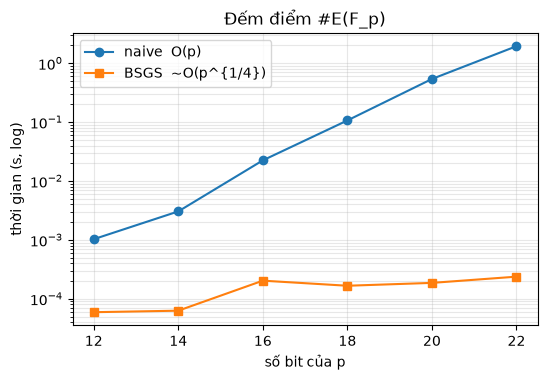

In [36]:
rng = random.Random(99)
bits_list, t_naive, t_bsgs = [], [], []
for bits in (12, 14, 16, 18, 20, 22):
    p = random_prime(rng, bits)
    E = Curve(p, rng.randrange(p), rng.randrange(p))
    if not E.is_nonsingular():
        continue
    t0 = time.perf_counter(); a = count_points_naive(E); t1 = time.perf_counter()
    b = count_points_bsgs(E, rng);                       t2 = time.perf_counter()
    assert a == b
    bits_list.append(bits); t_naive.append(t1 - t0); t_bsgs.append(t2 - t1)
    print(f"{bits:>2} bit | naive {t1 - t0:8.4f}s | bsgs {t2 - t1:8.4f}s")

plt.figure(figsize=(6, 3.8))
plt.semilogy(bits_list, t_naive, "o-", label="naive  O(p)")
plt.semilogy(bits_list, t_bsgs, "s-", label="BSGS  ~O(p^{1/4})")
plt.xlabel("số bit của p"); plt.ylabel("thời gian (s, log)"); plt.grid(alpha=.3, which="both"); plt.legend()
plt.title("Đếm điểm #E(F_p)")
plt.show()

## Tổng kết

**Đã có:** module sinh curve tất định theo seed, đếm điểm nhanh, phân loại 3 mode, kiểm chứng toán học, đọc/ghi CSV chuẩn D1.

**Gắn với checklist Thành viên A:**
- **T2** `curves/toy_curve_gen.py` ← bản notebook này (bản `.py` vẫn là file chạy chính, notebook dùng để giải thích/demo).
- **T3** sinh `data/D1_curves.csv` (n = 16..40 bit) → chạy `main([...])` với tham số ở mục 9b; sau đó viết `exhaustive_search.py` và `bsgs.py` đọc D1 qua `load_csv`.
- **T4** `gen_smooth_curves.py` có thể tái dùng `generate_curve(..., mode="smooth")`.
- Phụ thuộc: thứ tự cột `D1_COLUMNS` phải khớp `data/schema_definition.json` (task của Thành viên B, hiện *IN PROGRESS*) – nên đối chiếu lại khi schema chốt.

**Lưu ý kỹ thuật khi tiến tới đo hiệu năng**
- Python thuần chỉ phù hợp tới ~48 bit cho đếm điểm; hiện bản này đã kiểm thử tới 40 bit.
- Miller–Rabin tất định chỉ đảm bảo tới $\approx3{,}3\times10^{24}$ (đủ cho toy curve).
- Đường cong sinh ra **không** dành cho mật mã thực tế.

---

## Tài liệu tham khảo

**Đã tra cứu trực tuyến trong phiên này**
1. R. Schoof, *Counting points on elliptic curves over finite fields*, J. Théor. Nombres Bordeaux 7(1), 1995, tr. 219–254 – mô tả thuật toán BSGS đếm điểm và mẹo Mestre. <https://eudml.org/doc/93624>
2. J. Cremona, A. Sutherland, *On a theorem of Mestre and Schoof* – tính duy nhất của $\#E$ khi $q>229$ qua đường cong xoắn. <https://arxiv.org/pdf/0901.0120>
3. A. Sutherland, *MIT 18.783 Elliptic Curves, Lecture 7* – định lý Hasse, thuật toán Shanks/Mestre, bảng so sánh độ phức tạp các cách đếm điểm. <https://math.mit.edu/classes/18.783/2025/LectureSlides7.pdf>
4. Wikipedia, *Counting points on elliptic curves* (tổng quan: naive, BSGS, Schoof, SEA). <https://en.wikipedia.org/wiki/Counting_points_on_elliptic_curves>
5. Wikipedia, *Schoof's algorithm*. <https://en.wikipedia.org/wiki/Schoof%27s_algorithm>
6. Stanford PBC, *Counting Points* (định lý Hasse, vết Frobenius). <https://crypto.stanford.edu/pbc/notes/elliptic/count.html>
7. L. Chen, D. Moody, K. Randall, A. Regenscheid, A. Robinson, *NIST SP 800-186: Recommendations for Discrete Logarithm-based Cryptography: Elliptic Curve Domain Parameters*, 2023. <https://doi.org/10.6028/NIST.SP.800-186> (công bố cùng FIPS 186-5)

**Tài liệu chuẩn khác**
- NIST **FIPS 186-5** *Digital Signature Standard* (2023); IETF **RFC 6090** *Fundamental Elliptic Curve Cryptography Algorithms* – hai mục này cũng nằm trong task "Rà soát NIST SP 800-186, RFC 6090, FIPS 186-5" của checklist.
- D. Hankerson, A. Menezes, S. Vanstone, *Guide to Elliptic Curve Cryptography*, Springer, 2004.
- L. Washington, *Elliptic Curves: Number Theory and Cryptography*, 2nd ed., CRC Press, 2008.
- J. Silverman, *The Arithmetic of Elliptic Curves*, Springer.
- Với mục tiêu Track A: Pohlig–Hellman (1978), Pollard (1978) *Monte Carlo methods for index computation (mod p)*, Smart (1999) và Semaev/Satoh–Araki (1998) cho đường cong anomalous.